#Task: 02
## Creating Colab Notebook, executing SQL Queries and saving results in Google Cloud Storage as CSV files.

## Accessing the Google Account


In [91]:
from google.colab import auth
auth.authenticate_user()
print('Authenticated')

Authenticated


## Accessing Google Cloud Storage Instance

In [92]:
#It is the id of the project
proj_id = 'hpsa-analysis'
#It is the bucket name of the cloud storage
bucket_name = 'hpsa-analysis-bucket'

Setting up project.

In [93]:
#Setting up project with Google Colab Notebook
!gcloud config set project hpsa-analysis

Updated property [core/project].


## Importing Required Libraries


In [94]:
import sys
import pandas as pd
import seaborn as sns
from google.colab import files
import matplotlib.pyplot as plt
from google.cloud import bigquery
%load_ext google.colab.data_table

The google.colab.data_table extension is already loaded. To reload it, use:
  %reload_ext google.colab.data_table


##Quering Datasets

## Question: 01
### SQL Queries

In [95]:
sql_query = bigquery.Client(project=proj_id)
question_1 = sql_query.query('''
        SELECT Source_Name, HPSA_Score
          FROM `bigquery-public-data.sdoh_hrsa_shortage_areas.hpsa_dental_health`
           WHERE HPSA_Score IS NOT NULL ORDER BY HPSA_Score DESC;''').to_dataframe()

### Description of the Dataset

In [96]:
question_1.describe()

,HPSA_Score
count,30646.000000
mean,11.575246
std,8.039152
min,0.000000
25%,0.000000
50%,14.000000
75%,18.000000
max,26.000000


In [97]:
question_1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30646 entries, 0 to 30645
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Source_Name  30646 non-null  object
 1   HPSA_Score   30646 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 479.0+ KB


In [98]:
#Data type
question_1.dtypes

Source_Name    object
HPSA_Score      int64
dtype: object

### Peeping through the data

In [99]:
question_1.head(50)

,Source_Name,HPSA_Score
0,Portage Health Medical Group-Hancock Clinic,26
1,Portage Health Medical Group-Houghton,26
2,Portage Health Medical Group,26
3,ROSEBUD HOSPITAL,26
4,WANBLEE HEALTH CENTER,26
5,PINE RIDGE HOSPITAL,26
6,BULLHEAD HEALTH STATION,26
7,MANDERSON HEALTH STATION,26
8,FT. YATES HOSPITAL,26
9,CANNONBAL HEALTH STATION,26


## Question: 02
### SQL Queries

In [100]:
sql_query = bigquery.Client(project=proj_id)
question_2 = sql_query.query('''
        SELECT Source_Name, HPSA_Shortage
          FROM `bigquery-public-data.sdoh_hrsa_shortage_areas.hpsa_dental_health`
           WHERE HPSA_Score IS NOT NULL ORDER BY HPSA_Shortage DESC;''').to_dataframe()

### Description of the Dataset

In [101]:
question_2.describe()

,HPSA_Shortage
count,22199.000000
mean,11.762763
std,13.366579
min,-3.200000
25%,1.840000
50%,6.600000
75%,17.190000
max,58.200000


In [102]:
question_2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30646 entries, 0 to 30645
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Source_Name    30646 non-null  object 
 1   HPSA_Shortage  22199 non-null  float64
dtypes: float64(1), object(1)
memory usage: 479.0+ KB


### Peeping through the data

In [103]:
question_2.head(50)

,Source_Name,HPSA_Shortage
0,ME - Bedford Stuyvesant Service Area,58.2
1,ME - Bedford Stuyvesant Service Area,58.2
2,ME - Bedford Stuyvesant Service Area,58.2
3,ME - Bedford Stuyvesant Service Area,58.2
4,ME - Bedford Stuyvesant Service Area,58.2
5,ME - Bedford Stuyvesant Service Area,58.2
6,ME - Bedford Stuyvesant Service Area,58.2
7,ME - Bedford Stuyvesant Service Area,58.2
8,ME - Bedford Stuyvesant Service Area,58.2
9,ME - Bedford Stuyvesant Service Area,58.2


##Converting and Saving Query Results as CSV Files

By using the PANDAS library for data manipulation, query results are converted into CSV files.

In [104]:
#Converting data into CSV Files
question_1.to_csv('question_1_query.csv')
question_2.to_csv('question_2_query.csv')

## Uploading the converted CSV files to the Cloud Bucket

By utilizing the google cloud commands, uploading files to the google cloud bucket for the storage purposes.

In [105]:
#Query 1
# !gsutil cp /content/question_1_query.csv gs://hpsa-analysis-bucket

In [106]:
#Query 2
# !gsutil cp /content/question_2_query.csv gs://hpsa-analysis-bucket

##Cleaning the Data

###Downloading CSV files from Google Cloud Storage

Now downloading the CSV Files from the cloud bucket for data manipulation and performing data cleaning procedures.

In [107]:
#Query 1
!gsutil cp gs://hpsa-analysis-bucket/question_1_query.csv /content/question_1_query.csv

Copying gs://hpsa-analysis-bucket/question_1_query.csv...
/ [1 files][ 1017 KiB/ 1017 KiB]                                                
Operation completed over 1 objects/1017.8 KiB.                                   


In [108]:
#Query 2
!gsutil cp gs://hpsa-analysis-bucket/question_2_query.csv /content/question_2_query.csv

Copying gs://hpsa-analysis-bucket/question_2_query.csv...
/ [1 files][  1.0 MiB/  1.0 MiB]                                                
Operation completed over 1 objects/1.0 MiB.                                      


### After downloading the csv files, now saving into Dataframe from csv files

CSV files are converted into dataframe to perform tasks.

In [109]:
#Query 1
question_1_csv_data = pd.read_csv('/content/question_1_query.csv')

In [110]:
#Query 2
question_2_csv_data = pd.read_csv('/content/question_2_query.csv')

### Removing Excessive Column

To visualize and analyze proper dataset, unnecessary features/columns were omitted.

In [111]:
#Query 1
question_1_csv_data = question_1_csv_data.drop('Unnamed: 0', axis=1)

In [112]:
#Query 2
question_2_csv_data = question_2_csv_data.drop('Unnamed: 0', axis=1)

### Removing those rows that have duplicate data

To keep the quality of the dataset, duplicate rows and values were removed.

In [113]:
#Query 1
question_1_csv_data = question_1_csv_data.drop_duplicates()

In [114]:
#Query 2
question_2_csv_data = question_2_csv_data.drop_duplicates()

### Re-setting the index of the data

After removing unnecessary records, the dataset index was reset to better present the data.

Re-setting index

In [115]:
#Query 1
question_1_csv_data.set_index('Source_Name', inplace=True)

In [116]:
#Query 2
question_2_csv_data.set_index('Source_Name', inplace=True)

Setting new index

In [117]:
#Query 1
question_1_csv_data.reset_index(level=0, inplace=True)

In [118]:
#Query 2
question_2_csv_data.reset_index(level=0, inplace=True)

### Viewing Data after Cleaning

In [119]:
# Viewing question 1 query result
question_1_csv_data

,Source_Name,HPSA_Score
0,Portage Health Medical Group-Hancock Clinic,26
1,Portage Health Medical Group-Houghton,26
2,Portage Health Medical Group,26
3,ROSEBUD HOSPITAL,26
4,WANBLEE HEALTH CENTER,26
...,...,...
9418,Low Income/Migrant Farmworker - Northern Ventura,0
9419,Low Income - Guerneville,0
9420,Low Income - Healdsburg/Geyserville,0
9421,Low Income - El Mirage,0


Bar Plot

<BarContainer object of 10 artists>

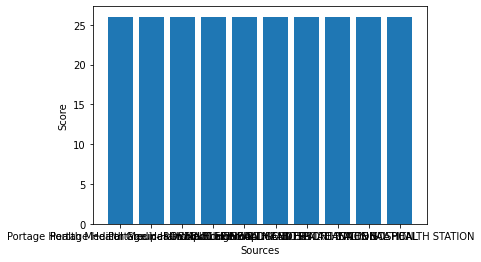

In [120]:
data = question_1_csv_data.drop_duplicates('Source_Name', keep='last')
source_name = data['Source_Name']
shortage = data['HPSA_Score']

plt.xlabel('Sources')
plt.ylabel('Score')
plt.bar(source_name[0:10], shortage[0:10])

In [121]:
# Viewing question 2 query result
question_2_csv_data

,Source_Name,HPSA_Shortage
0,ME - Bedford Stuyvesant Service Area,58.20
1,LI-Northwest Detroit SA,57.01
2,LI-Lee County,54.75
3,Li-West Palm Beach,53.39
4,Medicaid Eligible - Southwest Bronx,53.32
...,...,...
9475,Bond County,NaN
9476,LI-Cheyenne County,NaN
9477,McFarland/Delano,NaN
9478,Shafter/Wasco,NaN


<BarContainer object of 10 artists>

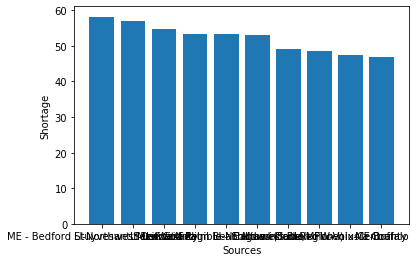

In [122]:
data = question_2_csv_data.drop_duplicates('Source_Name', keep='last')
source_name = data['Source_Name']
shortage = data['HPSA_Shortage']

plt.xlabel('Sources')
plt.ylabel('Shortage')
plt.bar(source_name[0:10], shortage[0:10])

In [123]:
question_2_csv_data['HPSA_Shortage']

0       58.20
1       57.01
2       54.75
3       53.39
4       53.32
        ...  
9475      NaN
9476      NaN
9477      NaN
9478      NaN
9479      NaN
Name: HPSA_Shortage, Length: 9480, dtype: float64

##Task: 03 Visualizing the Data from CSV Files

###Question: 01 Visualization

In this section of the coursework, an opensource visualization library have been put into work to present the data graphically.

### Line Graph
Plotting Line Graph to present the trend of the HSPA Score values

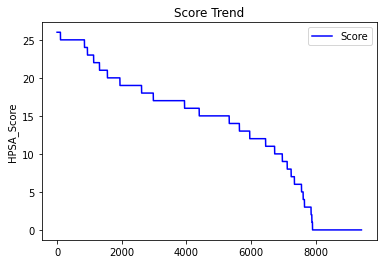

In [124]:
#Plotting line graph
plt.plot(question_1_csv_data['HPSA_Score'], color = 'b', label = "Score")
plt.ylabel('HPSA_Score')
plt.title('Score Trend')
plt.legend()
plt.show()

###Histogram

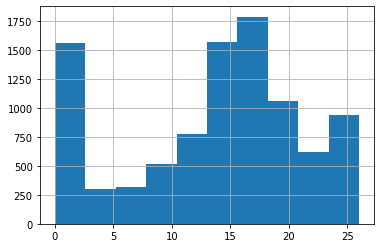

In [125]:
#Plotting Histogram of the Score
question_1_csv_data['HPSA_Score'].hist()

##Question: 02 SQL Query Visualization

###Line Graph

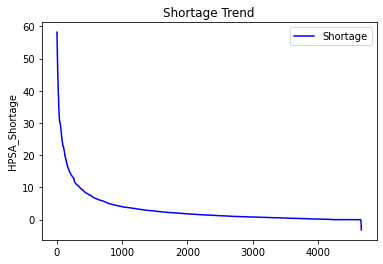

In [149]:
data = question_2_csv_data

plt.plot(question_2_csv_data['HPSA_Shortage'], color = 'b', label = "Shortage")
plt.ylabel('HPSA_Shortage')
plt.title('Shortage Trend')
plt.legend()
plt.show()

###Histogram

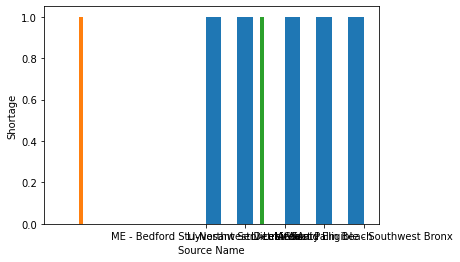

In [127]:
source = question_2_csv_data["Source_Name"]
minimum = question_2_csv_data['HPSA_Shortage'].min()
median = question_2_csv_data['HPSA_Shortage'].max()

plt.hist(source[0:5])
plt.hist(minimum)
plt.hist(maximum)
plt.xlabel("Source Name")
plt.ylabel("Shortage")
plt.show()

### HSPA_Score and HSPA_Shortage

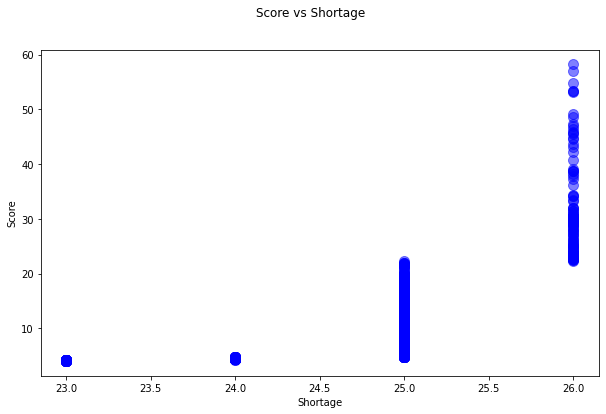

In [147]:
x = question_1_csv_data['HPSA_Score']
y = question_2_csv_data['HPSA_Shortage']
x.fillna(0)
y.fillna(0)

fig, ax = plt.subplots(1, figsize=(10, 6))
fig.suptitle('Score vs Shortage')

# Plot the scatter points
ax.scatter(x[:1000], y[:1000],
           color="blue",  
           s=100,         
           alpha=0.5,     
           linewidths=1)  
plt.xlabel("Shortage")
plt.ylabel("Score")
plt.show()

#### Line Graph between Score and Shortage

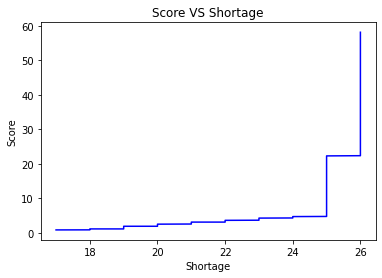

In [145]:
x = question_1_csv_data['HPSA_Score']
y = question_2_csv_data['HPSA_Shortage']
x.fillna(0)
y.fillna(0)

plt.plot(x[:3000], y[:3000], color = 'b')
plt.xlabel("Shortage")
plt.ylabel("Score")
plt.title('Score VS Shortage')
plt.show()

#### Boxplot

/usr/local/lib/python3.7/dist-packages/numpy/core/_asarray.py:83: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray
  return array(a, dtype, copy=False, order=order)


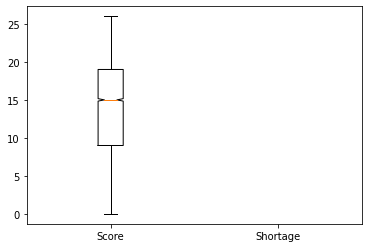

In [153]:
#Plotting BoxPlot
x = question_1_csv_data['HPSA_Score']
y = question_2_csv_data['HPSA_Shortage']
x.fillna(0)
y.fillna(0)

plt.boxplot((x, y), notch=True, sym="o", labels=["Score", "Shortage"])
plt.show()

# Part: 03 Querying the Google Cloud SQL Database

##SQL Queries using SQL Database

###Table: 01
#### Source Name and their respective HSPA Score

####Viewing Records

In [131]:
#Querying the tables
client = bigquery.Client(project=proj_id)
table_01_query_01 = client.query('''
    SELECT Source_Name, HPSA_Score
          FROM `hpsa_dataset.hpsa_score_table`
           WHERE HPSA_Score IS NOT NULL ORDER BY HPSA_Score DESC
    LIMIT 500
        ''').to_dataframe()

####Cleaning Data

To keep the quality and the integrity of the dataset, duplicate rows and values were removed.

In [132]:
table_01_query_01.drop_duplicates(inplace=True)

#### View records upto 500 rows

In [133]:
table_01_query_01

,Source_Name,HPSA_Score
0,Portage Health Medical Group,26
1,TRENTON MEDICAL CENTER INC,26
2,Republic of the Marshall Islands,26
3,Intercare Community Health Network,26
4,"SISKIYOU COMMUNITY HEALTH CENTER, INC.",26
...,...,...
495,"Regence Health Network, Inc.",25
496,Martin Luther King Jr Family Clinic Inc,25
497,SOUTH PLAINS RURAL HEALTH SERVICES INC,25
498,LACREEK DISTRICT CLINIC,25


#### View Records

In [134]:
#Querying the tables
client = bigquery.Client(project=proj_id)
table_01_query_02 = client.query('''
    SELECT Source_Name, HPSA_Score
          FROM `hpsa_dataset.hpsa_score_table`
           WHERE HPSA_Score IS NOT NULL ORDER BY HPSA_Score DESC
    LIMIT 1000
        ''').to_dataframe()

#### View records upto 1000 rows

In [135]:
table_01_query_02

,Source_Name,HPSA_Score
0,ROSEBUD HOSPITAL,26
1,Intercare Community Health Network,26
2,"KNOX, COUNTY OF",26
3,Yap State Department of Health Services,26
4,Republic of Palau,26
...,...,...
995,FT. THOMPSON HEALTH CENTER,24
996,MONTEZUMA CREEK CLINIC,24
997,BLANDING FAMILY HEALTH CENTER,24
998,MONUMENT VALLEY HEALTH CENTER,24


###Table: 02
#### Source Name and their respective HSPA Shortage values

####Viewing Records

In [136]:
#Querying the tables
client = bigquery.Client(project=proj_id)
table_02_query_01 = client.query('''
    SELECT Source_Name, HPSA_Shortage
          FROM `hpsa_dataset.hpsa_shortage_table`
           WHERE HPSA_Shortage IS NOT NULL ORDER BY HPSA_Shortage DESC
    LIMIT 500
        ''').to_dataframe()

#### View Records upto 500 rows

In [137]:
table_02_query_01

,Source_Name,HPSA_Shortage
0,ME - Bedford Stuyvesant Service Area,58.20
1,ME - Bedford Stuyvesant Service Area,58.20
2,ME - Bedford Stuyvesant Service Area,58.20
3,ME - Bedford Stuyvesant Service Area,58.20
4,ME - Bedford Stuyvesant Service Area,58.20
...,...,...
495,Medicaid Eligible - Southwest Bronx,53.32
496,Medicaid Eligible - Southwest Bronx,53.32
497,Medicaid Eligible - Southwest Bronx,53.32
498,Medicaid Eligible - Southwest Bronx,53.32


#### View Records




In [138]:
#Querying the tables
client = bigquery.Client(project=proj_id)
table_02_query_02 = client.query('''
    SELECT Source_Name, HPSA_Shortage
          FROM `hpsa_dataset.hpsa_shortage_table`
           WHERE HPSA_Shortage IS NOT NULL ORDER BY HPSA_Shortage DESC
    LIMIT 1000
        ''').to_dataframe()

#### View records upto 1000 rows

In [139]:
table_02_query_02

,Source_Name,HPSA_Shortage
0,ME - Bedford Stuyvesant Service Area,58.2
1,ME - Bedford Stuyvesant Service Area,58.2
2,ME - Bedford Stuyvesant Service Area,58.2
3,ME - Bedford Stuyvesant Service Area,58.2
4,ME - Bedford Stuyvesant Service Area,58.2
...,...,...
995,Medicaid Eligible - Northern Chicago,43.6
996,Medicaid Eligible - Northern Chicago,43.6
997,Medicaid Eligible - Northern Chicago,43.6
998,Medicaid Eligible - Northern Chicago,43.6
